In [2]:
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib
import pandas as pd

In [ ]:
# Data
action_phase_components = np.load("action_phase_components.npy")
action_phases = np.load("all_action_phases.npy", allow_pickle=True)
action_labels = np.load("all_action_labels.npy", allow_pickle=True)

In [ ]:
# CLustering
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, calinski_harabasz_score, davies_bouldin_score

# Load data (Replace these with actual loading methods)
action_phase_components = np.array(action_phase_components)  # Shape: (num_drivers, features)
action_labels = np.array(action_labels)  # Shape: (num_drivers, num_variables)
action_phases = np.array(action_phases, dtype=object)  # Shape: (num_drivers, num_variables, time_series_length)

# Step 1: Standardize Data
scaler = StandardScaler()
data_standardized = scaler.fit_transform(np.squeeze(action_phase_components))  # Remove unnecessary dimensions

# Step 2: Perform K-Means Clustering
n_clusters = 6  # Set the number of clusters
kmeans = KMeans(n_clusters=n_clusters, random_state=0, n_init=10)
clusters = kmeans.fit_predict(data_standardized)

# Step 3: Evaluate Clustering Performance
score_SS = silhouette_score(data_standardized, clusters)
score_CKI = calinski_harabasz_score(data_standardized, clusters)
score_DBS = davies_bouldin_score(data_standardized, clusters)

print(f"Silhouette Score: {score_SS:.4f}")
print(f"Calinski-Harabasz Score: {score_CKI:.4f}")
print(f"Davies-Bouldin Score: {score_DBS:.4f}")

# Step 4: Save Clustered Data
clustered_data = {}  # Dictionary to store results

for cluster_id in range(n_clusters):
    # Get indices of drivers in the cluster
    cluster_indices = np.where(clusters == cluster_id)[0]

    # Extract labels and phases for drivers in this cluster
    cluster_labels = action_labels[cluster_indices]
    cluster_phases = action_phases[cluster_indices]

    # Store the data
    clustered_data[cluster_id] = {
        "drivers": cluster_indices,  # List of driver indices
        "labels": cluster_labels,    # Labels for each variable
        "phases": cluster_phases     # Segmented driving data
    }

# Convert to a structured format (Pandas DataFrame) for easier saving and analysis
clustered_drivers_df = []

for cluster_id, cluster_info in clustered_data.items():
    for i, driver_id in enumerate(cluster_info["drivers"]):
        clustered_drivers_df.append({
            "Cluster": cluster_id,
            "Driver_ID": driver_id,
            "Labels": cluster_info["labels"][i].tolist(),  # Convert to list for readability
            "Phases": cluster_info["phases"][i].tolist()  # Convert to list
        })

# Convert to DataFrame and Save
df_clusters = pd.DataFrame(clustered_drivers_df)
save_path = "clustered_drivers_data.csv"
df_clusters.to_csv(save_path, index=False)
print(f"Clustered data saved successfully!")


Silhouette Score: 0.4385
Calinski-Harabasz Score: 15768.4381
Davies-Bouldin Score: 0.8089
Clustered data saved successfully!


In [67]:
import pandas as pd

# Display the first few rows of the DataFrame
print(df_clusters.head())

# If you want a more detailed view
import IPython.display as display
display.display(df_clusters)


   Cluster  Driver_ID        Labels  \
0        0         20  [L, I, I, D]   
1        0         21  [L, D, D, I]   
2        0         63  [I, I, I, H]   
3        0         74  [H, I, H, H]   
4        0         75  [H, I, H, H]   

                                              Phases  
0  [[14.054659843363092, 14.069575205880671, 14.0...  
1  [[14.2524852245188, 14.23570958522606, 14.2179...  
2  [[17.97420141225225, 17.98688038263236, 18.017...  
3  [[18.26768551409993, 18.34571067264968, 18.422...  
4  [[19.185598686836155, 19.16102147494837, 19.13...  


,Cluster,Driver_ID,Labels,Phases
0,0,20,"[L, I, I, D]","[[14.054659843363092, 14.069575205880671, 14.0..."
1,0,21,"[L, D, D, I]","[[14.2524852245188, 14.23570958522606, 14.2179..."
2,0,63,"[I, I, I, H]","[[17.97420141225225, 17.98688038263236, 18.017..."
3,0,74,"[H, I, H, H]","[[18.26768551409993, 18.34571067264968, 18.422..."
4,0,75,"[H, I, H, H]","[[19.185598686836155, 19.16102147494837, 19.13..."
...,...,...,...,...
14006,5,13904,"[D, I, I, I]","[[4.181383678789765, 4.374981953106773, 4.5714..."
14007,5,13907,"[L, H, I, H]","[[9.462715109836656, 9.544029922632532, 9.6281..."
14008,5,13986,"[I, H, H, H]","[[5.33757489491439, 5.260590083113596, 5.19024..."
14009,5,13987,"[D, I, D, D]","[[4.736069637060177, 4.744640587412133, 4.7637..."


✅ Figure successfully saved as: /Users/cielyao/surfdrive/Programming/Q2_Hetero_HDV/Dataprocessing/Lyft5_dataset/trainHH_2800/R1/manual_driver_visualization_20250129_134627.pdf


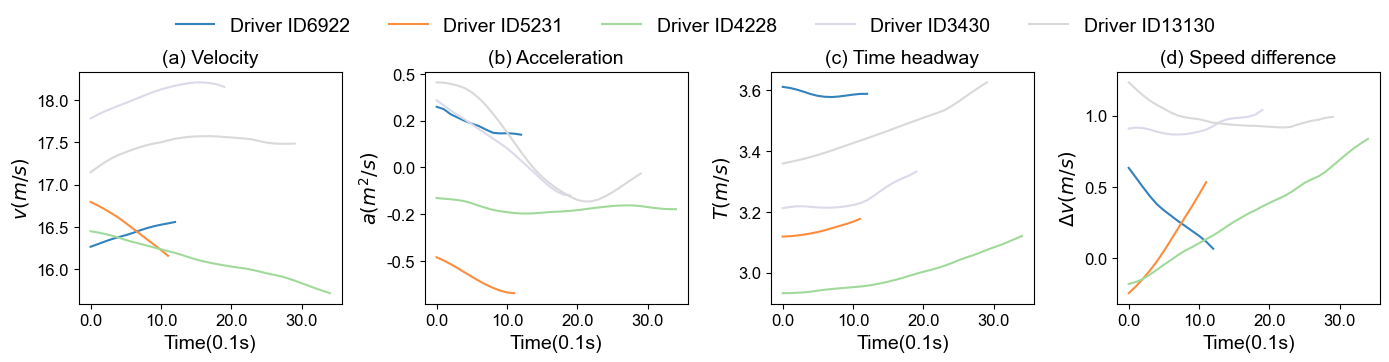

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import os
import random
from datetime import datetime
import matplotlib.cm as cm  # Import colormap

# Define the directory for saving figures
save_dir = "R1"

# Ensure the directory exists
if not os.path.exists(save_dir):
    os.makedirs(save_dir)

# Function to select drivers based on two variables' labels
def select_drivers(clustered_data, cluster_id, variable_1, label_1, variable_2, label_2, num_drivers=6, exclude_list=set()):
    """
    Selects drivers from a specific cluster whose two chosen variables match the target labels.

    Args:
        clustered_data (dict): Dictionary containing clustered drivers, labels, and phases.
        cluster_id (int): The cluster to select drivers from.
        variable_1 (int): First variable index (0=v, 1=a, 2=T, 3=delta_v).
        label_1 (str): Required label for the first variable.
        variable_2 (int): Second variable index.
        label_2 (str): Required label for the second variable.
        num_drivers (int): Number of drivers to select (default is 6).
        exclude_list (set): Set of already selected drivers to avoid repetition.

    Returns:
        selected_driver_indices (list): List of selected driver indices.
    """
    cluster_drivers = clustered_data[cluster_id]["drivers"]  # Get driver IDs in the cluster
    cluster_labels = clustered_data[cluster_id]["labels"]    # Get labels in the cluster

    # Filter drivers who match BOTH variable conditions
    filtered_drivers = [
        driver for i, driver in enumerate(cluster_drivers)
        if cluster_labels[i][variable_1] == label_1 and cluster_labels[i][variable_2] == label_2 and driver not in exclude_list
    ]

    # Randomly select up to num_drivers
    if len(filtered_drivers) > num_drivers:
        return random.sample(filtered_drivers, num_drivers)
    return filtered_drivers  # Return whatever is available

selected_cluster = 0  # Choose a specific cluster

# **Manually Select Driver IDs**
selected_driver_ids = [6922, 5231, 4228, 3430, 13130]  # Change to any 6 driver IDs you want

# Function to visualize manually selected drivers
def visualize_selected_drivers(selected_drivers):
    if not selected_drivers:
        print("No drivers selected for visualization.")
        return

    fig, axes = plt.subplots(1, 4, figsize=(14, 3.5), sharex=True)

    # Generate a unique filename with a timestamp
    timestamp = datetime.now().strftime("%Y%m%d_%H%M%S")
    save_path = os.path.join(save_dir, f"manual_driver_visualization_{timestamp}.pdf")

    # Use a colormap for distinct driver colors
    cmap = cm.get_cmap('tab20c', len(selected_drivers))

    labels = [f'Driver ID{driver_id}' for driver_id in selected_drivers]

    # Loop through selected drivers and correctly map their phase data
    for idx, driver_id in enumerate(selected_drivers):
        try:
            driver_idx = clustered_data[selected_cluster]["drivers"].tolist().index(driver_id)  # Get index in cluster
            phase_data = clustered_data[selected_cluster]["phases"][driver_idx]  # Correct mapping

            v = phase_data[0]  # Velocity
            a = phase_data[1]  # Acceleration
            T = phase_data[2]  # Time headway
            delta_v = phase_data[3]  # Speed difference

            color = cmap(idx)  # Get a color from the colormap

            # Plot each variable in its respective subplot
            axes[0].plot(v, label=labels[idx], color=color)
            axes[1].plot(a, color=color)
            axes[2].plot(T*0.1, color=color)
            axes[3].plot(delta_v, color=color)
        except ValueError:
            print(f"❌ Warning: Driver {driver_id} not found in the cluster!")
        except Exception as e:
            print(f"❌ Error plotting driver {driver_id}: {e}")

    # Customize subplots
    axes[0].set_ylabel('$v(m/s)$')
    axes[0].set_xlabel('Time(0.1s)')
    axes[0].set_title('(a) Velocity')

    axes[1].set_ylabel('$a(m^2/s)$')
    axes[1].set_xlabel('Time(0.1s)')
    axes[1].set_title('(b) Acceleration')

    axes[2].set_ylabel('$T(m/s)$')
    axes[2].set_xlabel('Time(0.1s)')
    axes[2].set_title('(c) Time headway')

    axes[3].set_ylabel('$\Delta v(m/s)$')
    axes[3].set_xlabel('Time(0.1s)')
    axes[3].set_title('(d) Speed difference')

    # Format tick labels to one decimal place
    for ax in axes:
        ax.yaxis.set_major_formatter(ticker.FuncFormatter(lambda x, _: f'{x:.1f}'))  
        ax.xaxis.set_major_formatter(ticker.FuncFormatter(lambda x, _: f'{x:.1f}'))  

    # Add a single legend for all subplots
    fig.legend(labels, loc='upper center', ncol=6, bbox_to_anchor=(0.5, 1.05), frameon=False)

    # Adjust layout for better visualization
    plt.tight_layout(rect=[0, 0, 1, 0.95])  

    # Save the figure as a PDF
    try:
        plt.savefig(save_path, format="pdf", bbox_inches="tight")
        print(f"✅ Figure successfully saved as: {save_path}")
    except Exception as e:
        print(f"❌ Error saving figure: {e}")

    # Show the figure in the notebook
    plt.show()

# Call the function to visualize the manually selected drivers
visualize_selected_drivers(selected_driver_ids)